# 2. Preprocesamiento y filtrado de las señales

## 2.0 Configuración e importes

In [47]:
%load_ext autoreload
%autoreload 2

import sys
import os
# --- Subir un nivel (..) para encontrar procesamiento_eeg.py en la raíz ---
sys.path.append(os.path.abspath('..'))

# --- Imports ---
import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import procesamiento_eeg as eeg
import random

# --- Ruta a la carpeta ---
ruta_datos = '../datos/Segmented_Data'

df_reporte = eeg.auditar_dataset_segmentado(ruta_datos)
sujetos_excluidos = ['s19']

lista_archivos = [
    a for a in df_reporte['archivo'] 
    if not any(a.startswith(s) for s in sujetos_excluidos)
]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
--- Auditoría de calidad sobre 40 archivos ---

Resumen del Control de Calidad:
Archivos válidos: 40 / 40
Todos los archivos pasaron el control de calidad perfectamente


## 2.1 Análisis exploratorio y decisiones de filtrado

Antes de realizar el filtrado, se lleva a cabo una exploración temporal y espectral de los registros EEG para identificar posibles fuentes de ruido. Para ello, la función `explorar_multicanal_tiempo_y_psd` selecciona aleatoriamente algunos registros y se visualiza el comportamiento de cada uno de sus canales en tiempo y en frecuencia.

En primer lugar, se visualiza la señal en el dominio temporal utilizando un fragmento inicial de `seg_tiempo` segundos. 

Luego, se calcula una densidad espectral de potencia (PSD) preliminar mediante el método de Welch.

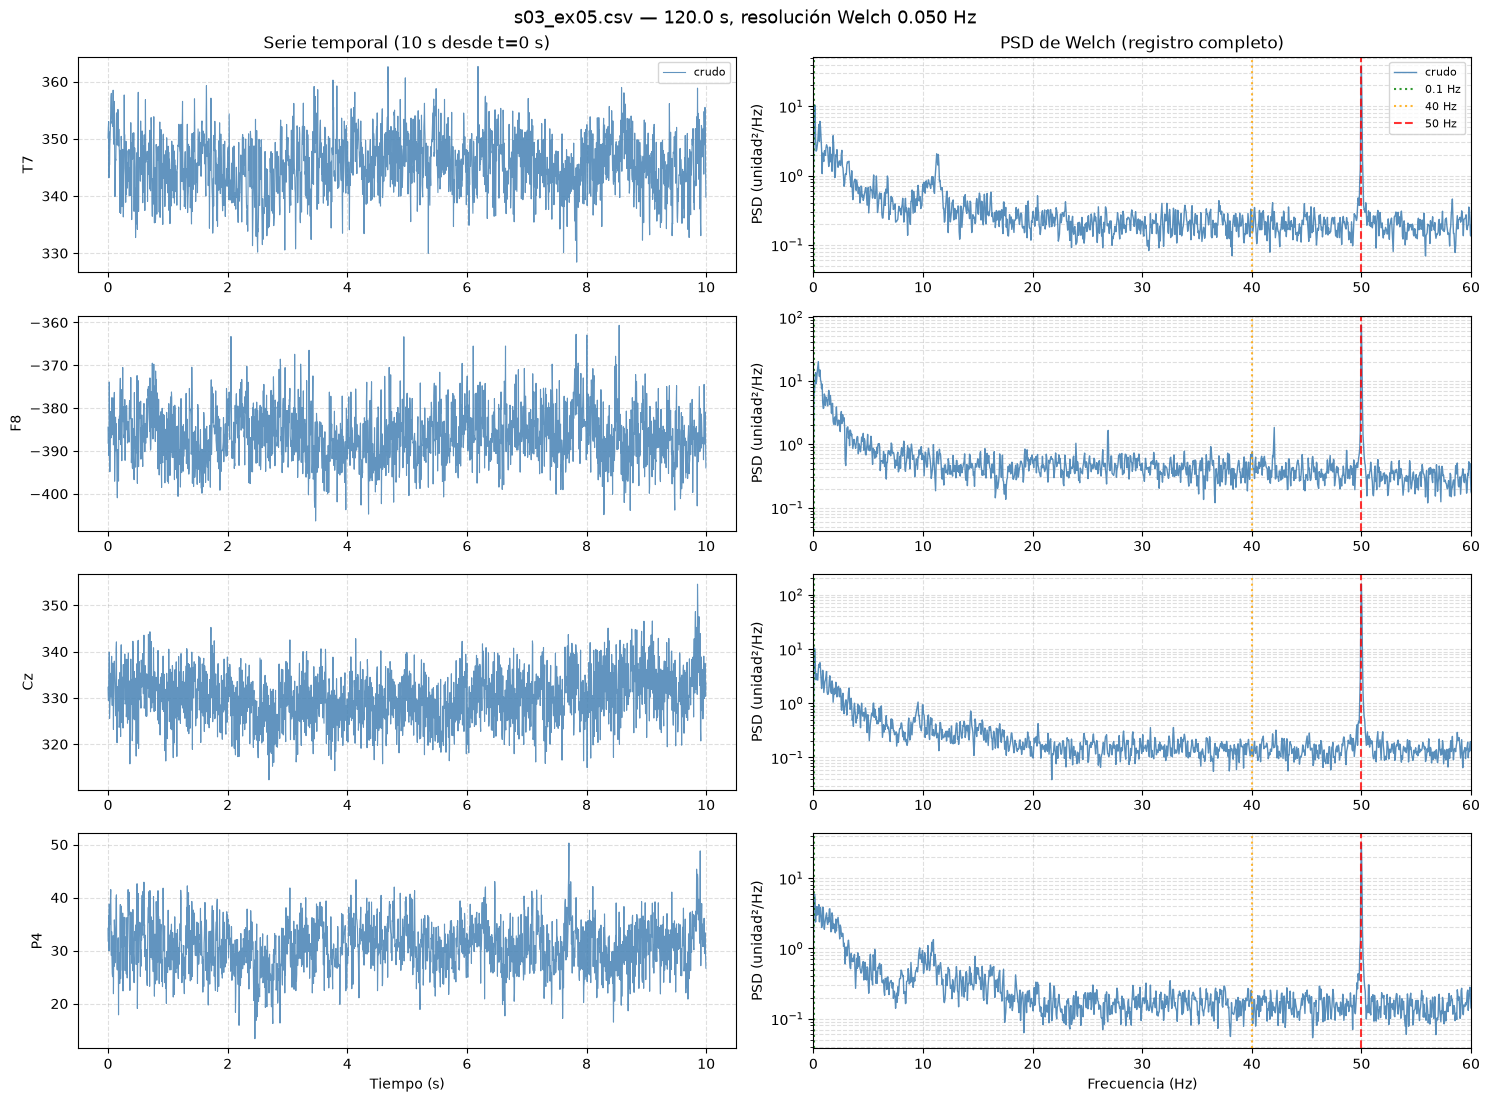

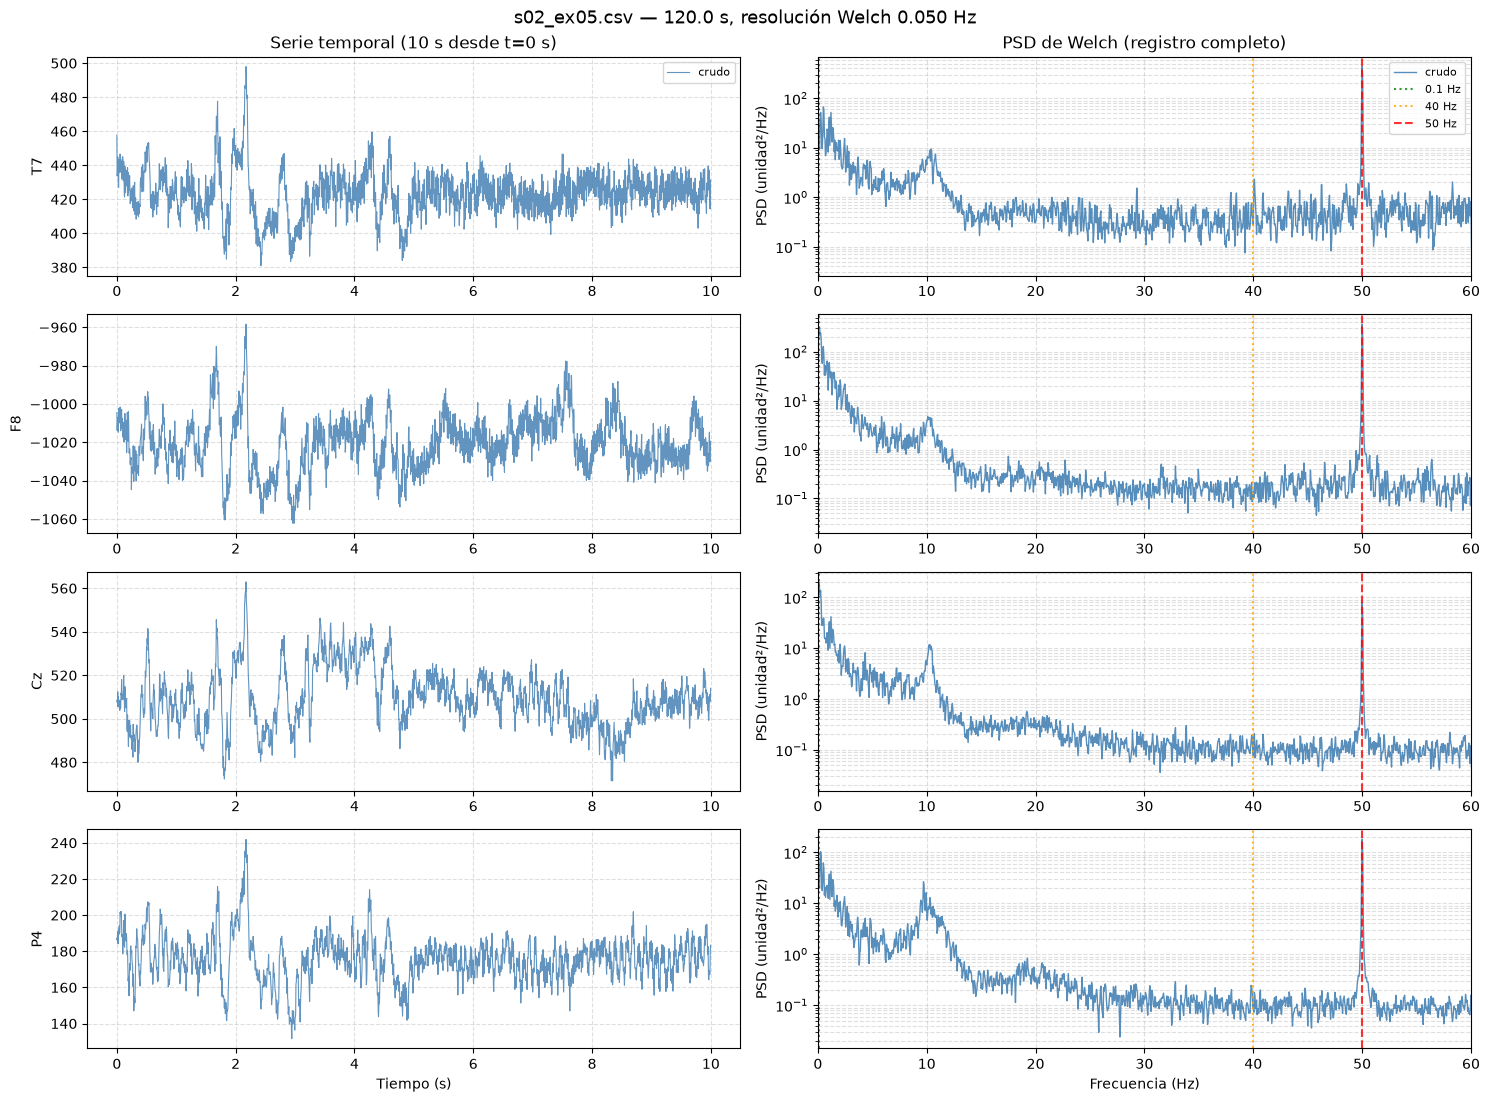

In [48]:
sel = eeg.explorar_registros({"crudo": ruta_datos}, lista_archivos, n_muestras=2, seed=None, fs=200)

Se observa en todos los casos un claro pico en 50 Hz correspondiente a los acoplamientos inductivos y capacitivos de la red eléctrica. 

Por otro lado, se evidencia en los gráficos temporales una deriva u oscilación lenta, especialmente en los canales F8 y Cz.

El decaimiento aperiódico característico de la señal se observa en todos los registros, con la actividad oscilatoria en la banda Alfa (8-13 Hz) sobresaliendo.

De este modo, se justifica la utilización de:
 - **Filtro Notch de 50 Hz** para contrarrestar la interferencia de red.
 - **Filtro pasabandas con frecuencias de corte 0,1 Hz y 40 Hz**: se busca atenuar las derivas de muy baja frecuencia y el ruido de alta frecuencia. La elección de estos límites se fundamenta en antecedentes de procesamiento de EEG en contextos auditivos lingüísticos. Markovic et. al (2017), en un estudio sobre actividad cerebral durante la escucha musical, utilizaron inicialmente un filtro de 0,1 - 30 Hz, mientras que Wagner et al. (2023), en una investigación sobre el procesamiento de patrones lingüísticos nativos y no nativos, emplearon un rango de 0,1 - 55 Hz. A partir de estos antecedentes, se propone un límite superior de 40 Hz que permite analizar las bandas delta, theta, alfa y beta, además de la porción inferior de gamma (30 - 40 Hz). 

A diferencia de la versión filtrada del dataset de PhysioNet, que utiliza un filtro pasabandas de 1 - 40 Hz, se busca conservar las componentes de baja frecuencia, incluida la banda delta. Esta decisión se basa en el trabajo Classification of Native and non-native songs, neutral music, and resting state of human brain from EEG-based auditory evoked potential using explainable features, de Rajbdad et al. (2026), que destaca el potencial de los ritmos delta como marcadores para discriminar entre distintas condiciones auditivas. 



## 2.3 Aplicación de filtros

In [49]:
ruta_filtrados = '../datos/Datos_Filtrados'
os.makedirs(ruta_filtrados, exist_ok=True)

for idx, nombre_archivo in enumerate(lista_archivos, 1):
    ruta_in = os.path.join(ruta_datos, nombre_archivo)
    df_raw = pd.read_csv(ruta_in)
    
    # Llamada a la función del .py
    df_filt = eeg.aplicar_filtros_eeg(df_raw, fs=200)
    
    ruta_out = os.path.join(ruta_filtrados, nombre_archivo)
    df_filt.to_csv(ruta_out, index=False)
    
    print(f" [{idx}/{len(lista_archivos)}] Procesado y guardado: {nombre_archivo}")

print(f"\n Todos los archivos filtrados quedaron guardados en '{ruta_filtrados}'.")

 [1/38] Procesado y guardado: s01_ex05.csv
 [2/38] Procesado y guardado: s01_ex06.csv
 [3/38] Procesado y guardado: s02_ex05.csv
 [4/38] Procesado y guardado: s02_ex06.csv
 [5/38] Procesado y guardado: s03_ex05.csv
 [6/38] Procesado y guardado: s03_ex06.csv
 [7/38] Procesado y guardado: s04_ex05.csv
 [8/38] Procesado y guardado: s04_ex06.csv
 [9/38] Procesado y guardado: s05_ex05.csv
 [10/38] Procesado y guardado: s05_ex06.csv
 [11/38] Procesado y guardado: s06_ex05.csv
 [12/38] Procesado y guardado: s06_ex06.csv
 [13/38] Procesado y guardado: s07_ex05.csv
 [14/38] Procesado y guardado: s07_ex06.csv
 [15/38] Procesado y guardado: s08_ex05.csv
 [16/38] Procesado y guardado: s08_ex06.csv
 [17/38] Procesado y guardado: s09_ex05.csv
 [18/38] Procesado y guardado: s09_ex06.csv
 [19/38] Procesado y guardado: s10_ex05.csv
 [20/38] Procesado y guardado: s10_ex06.csv
 [21/38] Procesado y guardado: s11_ex05.csv
 [22/38] Procesado y guardado: s11_ex06.csv
 [23/38] Procesado y guardado: s12_ex05.c

## 2.4 Comparación pre y post-filtrado

Se reutiliza la función `explorar_multicanal_tiempo_y_psd` pero ahora utilizando Datos_Filtrados.

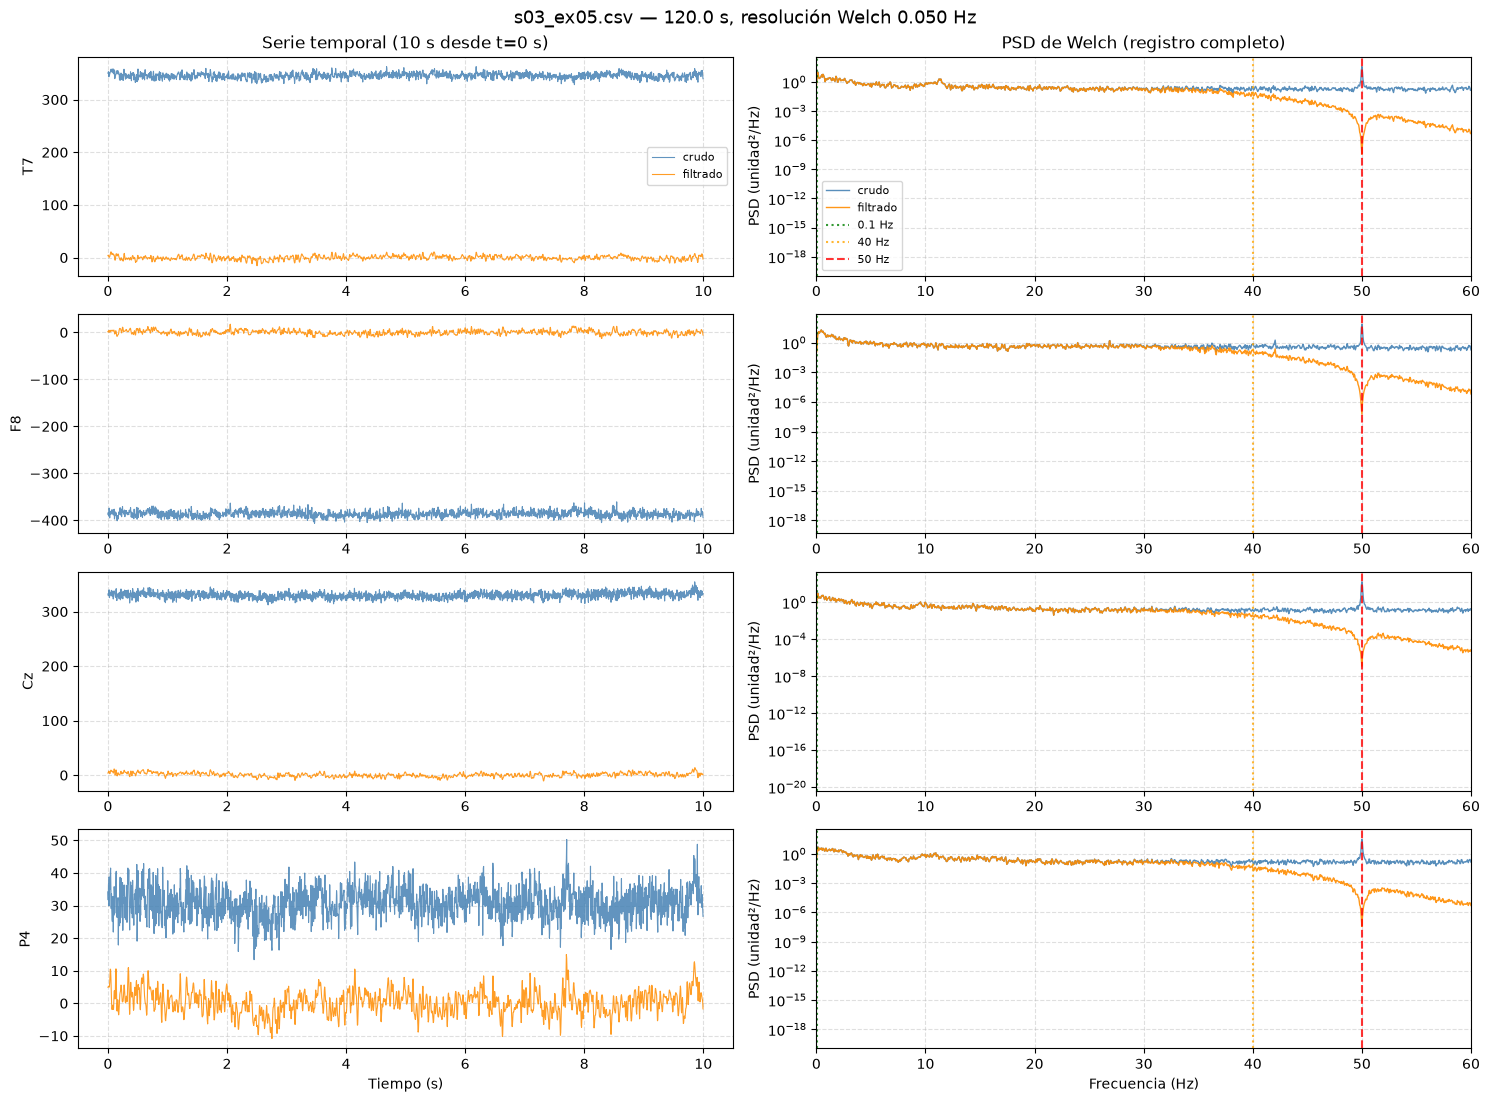

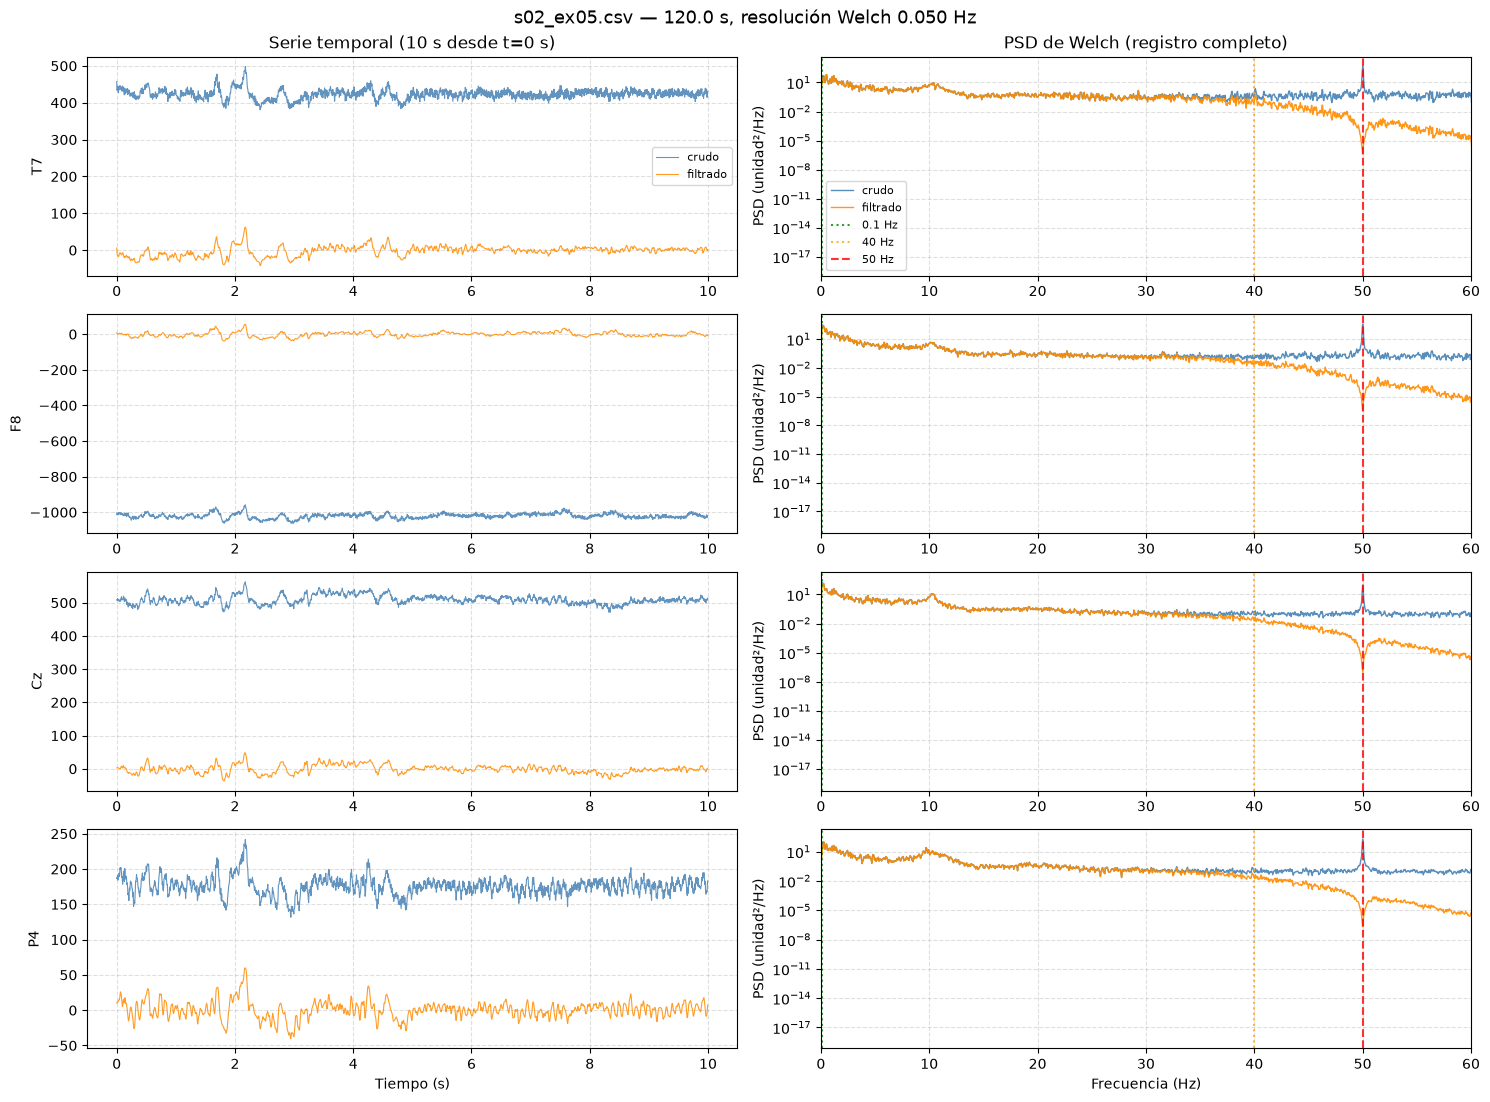

['s03_ex05.csv', 's02_ex05.csv']

In [50]:
eeg.explorar_registros({"crudo": ruta_datos, "filtrado": ruta_filtrados}, sel, n_muestras=len(sel), fs=200)